In [2]:
import torch
import torch.nn as nn
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

PyTorch: 2.14.1+cpu
Torchvision: 0.29.2+cpu
Device: CPU


In [3]:
import os

cover_path = "data/raw/Cover"
stego_path = "data/raw/Stego"

print("Cover folder exists:", os.path.exists(cover_path))
print("Stego folder exists:", os.path.exists(stego_path))

Cover folder exists: True
Stego folder exists: True


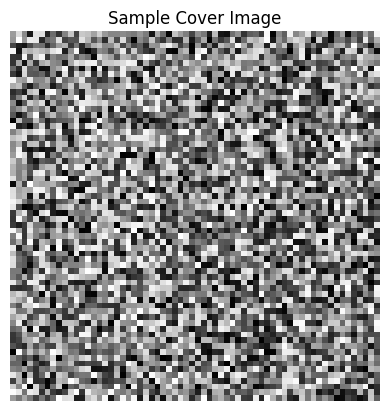

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Create a sample grayscale image
sample = np.random.randint(0, 256, (64, 64), dtype=np.uint8)

# Save the image
Image.fromarray(sample).save("data/raw/Cover/sample.png")

# Display the image
plt.imshow(sample, cmap="gray")
plt.title("Sample Cover Image")
plt.axis("off")
plt.show()

In [5]:
# Read the saved image
image = Image.open("data/raw/Cover/sample.png").convert("L")

# Convert image to NumPy array
image_array = np.array(image)

# Convert NumPy array to PyTorch Tensor
image_tensor = torch.tensor(image_array, dtype=torch.float32)

# Normalize pixel values
image_tensor = image_tensor / 255.0

print("Image shape:", image_array.shape)
print("Tensor shape:", image_tensor.shape)
print("Minimum value:", image_tensor.min().item())
print("Maximum value:", image_tensor.max().item())

Image shape: (64, 64)
Tensor shape: torch.Size([64, 64])
Minimum value: 0.0
Maximum value: 1.0


In [6]:
# Add channel dimension
image_tensor = image_tensor.unsqueeze(0)

# Add batch dimension
image_tensor = image_tensor.unsqueeze(0)

print("Final image shape:", image_tensor.shape)

Final image shape: torch.Size([1, 1, 64, 64])


In [7]:
cnn_layer = nn.Conv2d(
    in_channels=1,
    out_channels=8,
    kernel_size=3,
    padding=1
)

features = cnn_layer(image_tensor)

print("Input shape:", image_tensor.shape)
print("Output shape:", features.shape)

Input shape: torch.Size([1, 1, 64, 64])
Output shape: torch.Size([1, 8, 64, 64])


[W1106 23:36:30.807760134 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


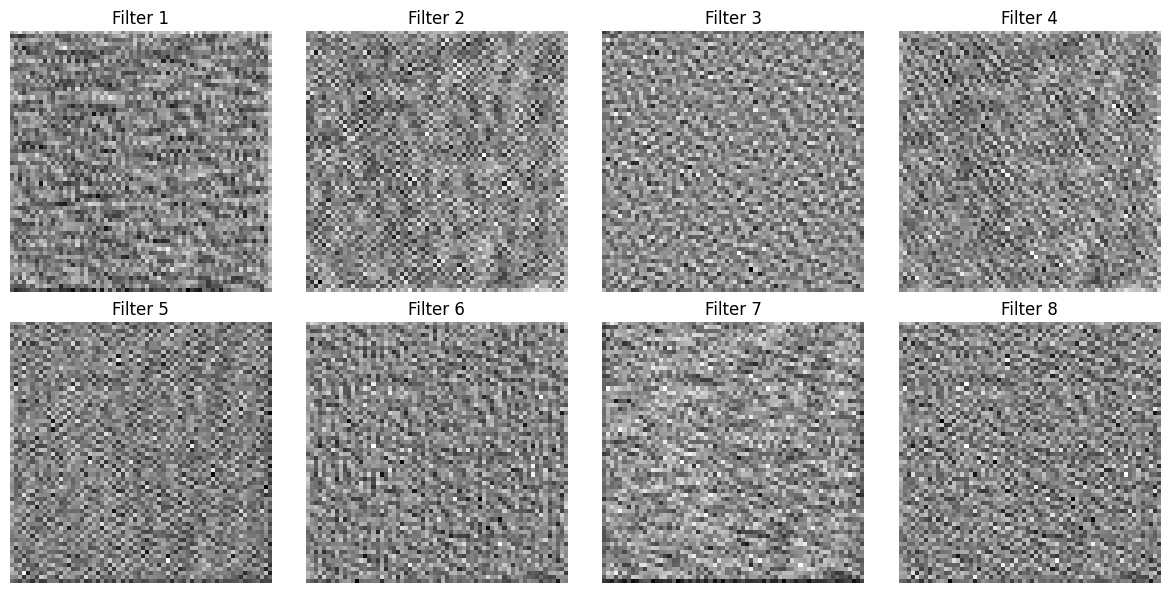

In [8]:
# Convert feature maps to NumPy
feature_maps = features.detach().squeeze(0).numpy()

# Display the 8 feature maps
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[i], cmap="gray")
    ax.set_title(f"Filter {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# ReLU activation
relu = nn.ReLU()
activated_features = relu(features)

# Max Pooling
pool = nn.MaxPool2d(kernel_size=2, stride=2)
pooled_features = pool(activated_features)

print("Before Pooling:", activated_features.shape)
print("After Pooling:", pooled_features.shape)

Before Pooling: torch.Size([1, 8, 64, 64])
After Pooling: torch.Size([1, 8, 32, 32])


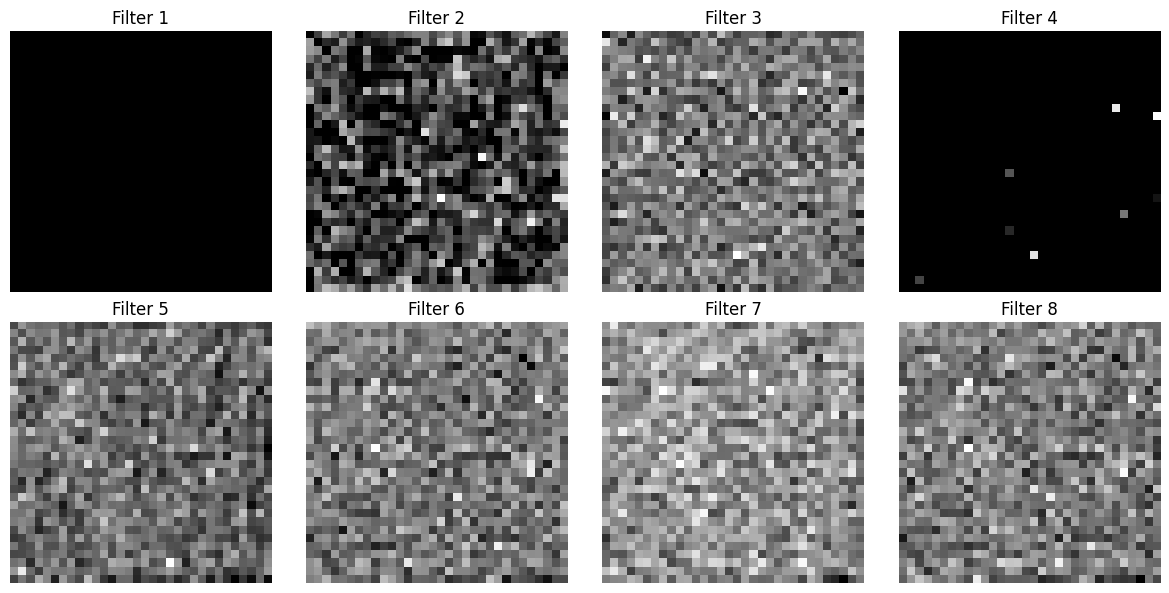

In [10]:
pooled_images = pooled_features.detach().squeeze(0).numpy()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(pooled_images[i], cmap="gray")
    ax.set_title(f"Filter {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

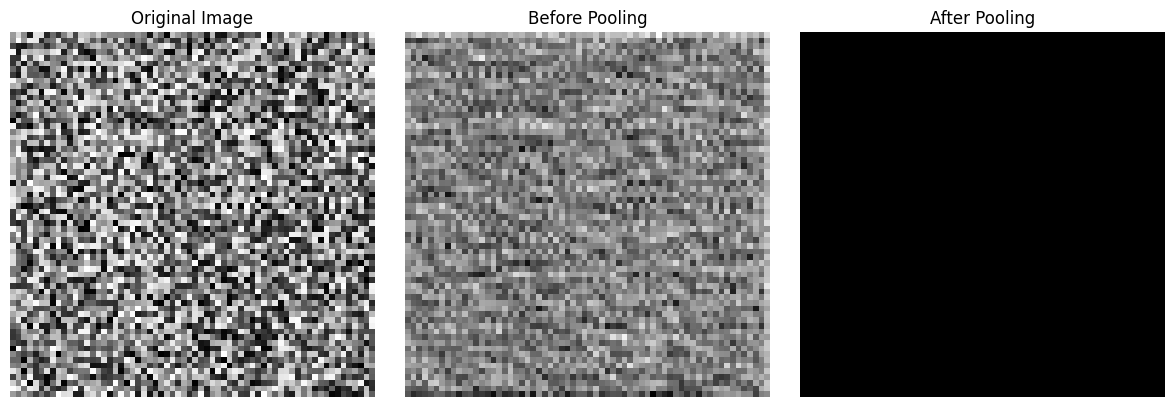

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Original image
axes[0].imshow(image_tensor.squeeze().numpy(), cmap="gray")
axes[0].set_title("Original Image")

# First feature map
axes[1].imshow(feature_maps[0], cmap="gray")
axes[1].set_title("Before Pooling")

# First pooled feature map
axes[2].imshow(pooled_images[0], cmap="gray")
axes[2].set_title("After Pooling")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
print("Before ReLU:")
print("Min:", features.min().item())
print("Max:", features.max().item())

print("\nAfter ReLU:")
print("Min:", activated_features.min().item())
print("Max:", activated_features.max().item())

print("\nAfter Pooling:")
print("Min:", pooled_features.min().item())
print("Max:", pooled_features.max().item())

Before ReLU:
Min: -1.0113859176635742
Max: 1.081636667251587

After ReLU:
Min: 0.0
Max: 1.081636667251587

After Pooling:
Min: 0.0
Max: 1.081636667251587


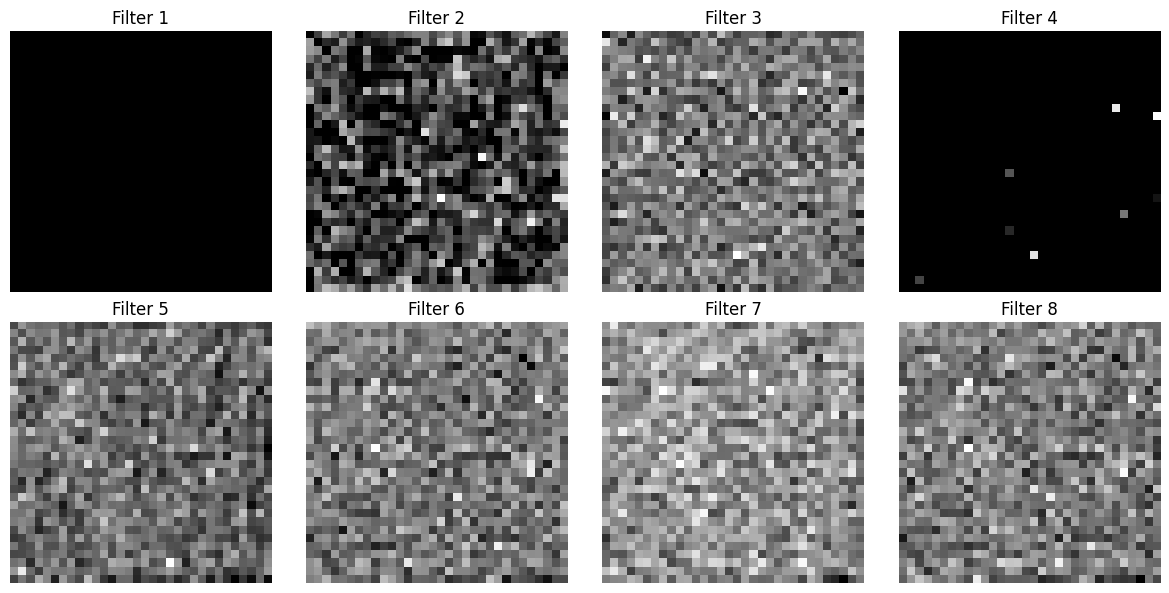

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(pooled_images[i], cmap="gray")
    ax.set_title(f"Filter {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
for i in range(8):
    current_filter = pooled_images[i]

    print(
        f"Filter {i + 1}:",
        "Min =", current_filter.min(),
        "Max =", current_filter.max(),
        "Mean =", current_filter.mean()
    )

Filter 1: Min = 0.0 Max = 0.0 Mean = 0.0
Filter 2: Min = 0.0 Max = 0.3671472 Mean = 0.09697294
Filter 3: Min = 0.0068402737 Max = 0.7616757 Mean = 0.35530078
Filter 4: Min = 0.0 Max = 0.082253814 Mean = 0.00032971374
Filter 5: Min = 0.01524879 Max = 0.85543483 Mean = 0.36927414
Filter 6: Min = 0.07866126 Max = 0.89719284 Mean = 0.46385798
Filter 7: Min = 0.31393522 Max = 1.0816367 Mean = 0.75784516
Filter 8: Min = 0.033738945 Max = 0.62882113 Mean = 0.32026255


In [15]:
class SteganalysisCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            # First convolution block
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(16 * 16 * 16, 64),

            nn.ReLU(),

            nn.Linear(64, 2)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


model = SteganalysisCNN().to(device)

print(model)

SteganalysisCNN(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [16]:
test_input = torch.randn(1, 1, 64, 64)

output = model(test_input)

print("Input:", test_input.shape)
print("Output:", output.shape)
print("Output values:", output)

Input: torch.Size([1, 1, 64, 64])
Output: torch.Size([1, 2])
Output values: tensor([[-0.0684,  0.1558]], grad_fn=<AddmmBackward0>)


[W1106 23:46:01.969023096 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1106 23:46:01.970942413 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


In [17]:
probabilities = torch.softmax(output, dim=1)

print("Cover probability:", probabilities[0][0].item())
print("Stego probability:", probabilities[0][1].item())

Cover probability: 0.44419360160827637
Stego probability: 0.5558063983917236


In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

cover_dir = "data/raw/Cover"
stego_dir = "data/raw/Stego"

os.makedirs(cover_dir, exist_ok=True)
os.makedirs(stego_dir, exist_ok=True)

np.random.seed(42)

for i in range(50):

    # Create a grayscale image
    image = np.random.randint(
        30, 220, (64, 64), dtype=np.uint8
    )

    # Save original image
    Image.fromarray(image).save(
        f"{cover_dir}/cover_{i}.png"
    )

    # Hide a simple binary message in the least significant bit
    message = np.random.randint(
        0, 2, (64, 64), dtype=np.uint8
    )

    stego_image = (image & 254) | message

    Image.fromarray(stego_image).save(
        f"{stego_dir}/stego_{i}.png"
    )

print("Dataset created successfully!")
print("Cover images:", len(os.listdir(cover_dir)))
print("Stego images:", len(os.listdir(stego_dir)))

Dataset created successfully!
Cover images: 51
Stego images: 50


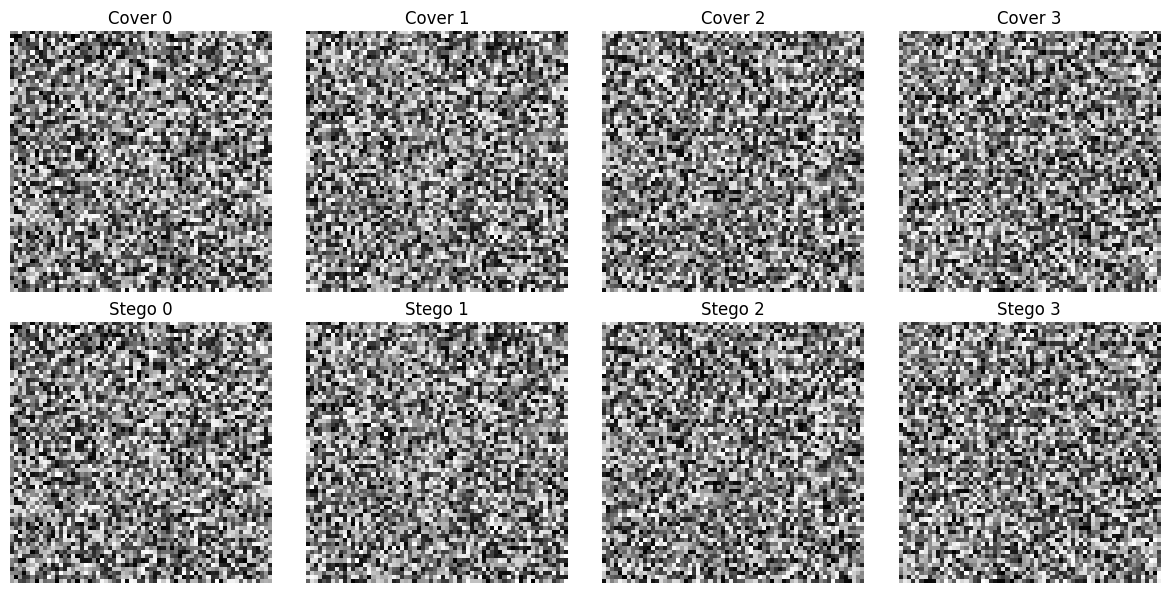

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):

    cover = Image.open(f"{cover_dir}/cover_{i}.png")
    stego = Image.open(f"{stego_dir}/stego_{i}.png")

    axes[0, i].imshow(cover, cmap="gray")
    axes[0, i].set_title(f"Cover {i}")

    axes[1, i].imshow(stego, cmap="gray")
    axes[1, i].set_title(f"Stego {i}")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [20]:
import os
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

cover_dir = "data/raw/Cover"
stego_dir = "data/raw/Stego"

os.makedirs(cover_dir, exist_ok=True)
os.makedirs(stego_dir, exist_ok=True)

np.random.seed(42)

for i in range(50):
    # Create a grayscale image
    image = Image.new("L", (64, 64), color=180)
    draw = ImageDraw.Draw(image)

    # Add simple shapes
    draw.rectangle((5, 5, 30, 30), fill=80)
    draw.ellipse((25, 20, 55, 50), fill=220)
    draw.line((0, 60, 63, 0), fill=120, width=2)

    # Add slight variation
    pixels = np.array(image).astype(np.int16)
    noise = np.random.randint(-5, 6, (64, 64))
    pixels = np.clip(pixels + noise, 0, 255).astype(np.uint8)

    # Original image
    cover = pixels.copy()

    # Hide random bits in 10% of pixels
    stego = cover.copy()
    mask = np.random.random((64, 64)) < 0.10
    hidden_bits = np.random.randint(0, 2, (64, 64))

    stego[mask] = (stego[mask] & 254) | hidden_bits[mask]

    Image.fromarray(cover).save(f"{cover_dir}/cover_{i}.png")
    Image.fromarray(stego).save(f"{stego_dir}/stego_{i}.png")

print("New dataset created successfully!")

New dataset created successfully!


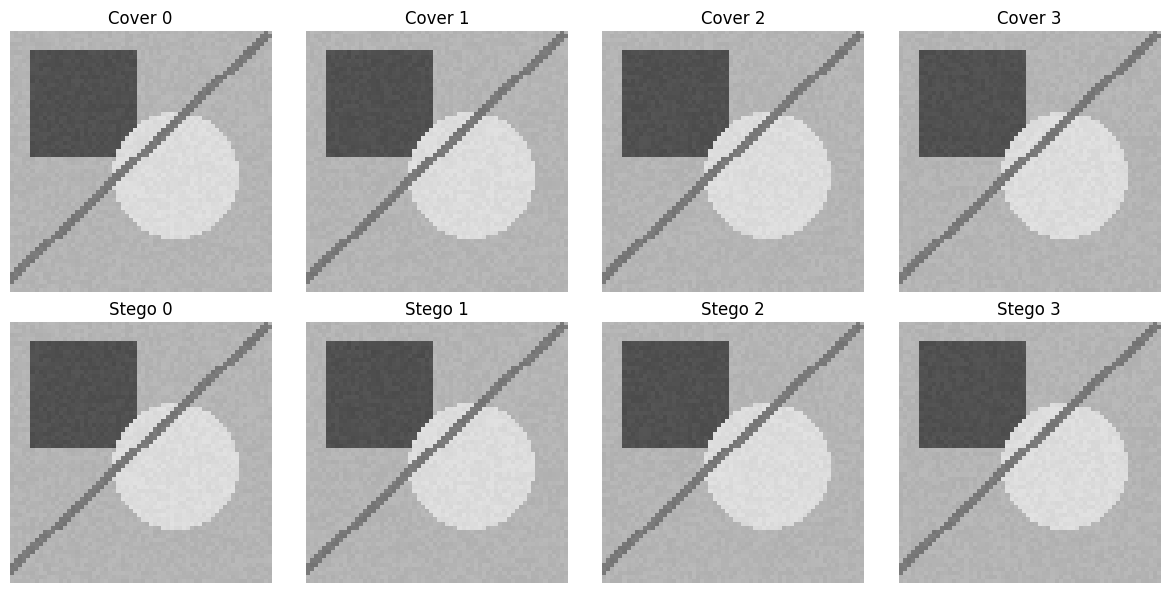

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    cover = Image.open(f"data/raw/Cover/cover_{i}.png")
    stego = Image.open(f"data/raw/Stego/stego_{i}.png")

    axes[0, i].imshow(cover, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(f"Cover {i}")

    axes[1, i].imshow(stego, cmap="gray", vmin=0, vmax=255)
    axes[1, i].set_title(f"Stego {i}")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()